# Lab 2B: traffic lights and signs with a pretrained YOLO

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches
from ultralytics import YOLO

from bdd_data import (
    CLASS_COLORS,
    CLASSES,
    draw_boxes,
    load_image,
    load_splits,
    prepare_data,
    print_summary,
)

## Data loading

In [2]:
prepare_data()
train_samples, dev_samples, test_samples = load_splits()
for name, samples in [
    ("train", train_samples),
    ("dev", dev_samples),
    ("test", test_samples),
]:
    print_summary(name, samples)

train: 1000 images, 5898 boxes | sign 3439, light_red 565, light_yellow 55, light_green 1097, light_unknown 742
dev: 500 images, 2996 boxes | sign 1716, light_red 340, light_yellow 20, light_green 509, light_unknown 411
test: 1000 images, 6095 boxes | sign 3516, light_red 570, light_yellow 57, light_green 1139, light_unknown 813


## Pretrained YOLO (COCO)

Only the COCO classes that matter here are kept. The images are 1280x720 and half of the boxes are under 20 px high, so YOLO runs at `IMGSZ = 1280` instead of the default 640, which would shrink small lights to a few pixels.

In [3]:
YOLO_WEIGHTS = "yolo26n.pt"  # downloaded on first use
IMGSZ = 1280
CONF = 0.25

model = YOLO(YOLO_WEIGHTS)
COCO_IDS = [i for i, n in model.names.items() if n in ("traffic light", "stop sign")]
print({i: model.names[i] for i in COCO_IDS})

{9: 'traffic light', 11: 'stop sign'}


In [4]:
def yolo_predict(model, samples, conf=CONF, imgsz=IMGSZ):
    """YOLO detections of the COCO_IDS classes for every image, and the mean speed in fps.
    Returns ({file_name: {"boxes": (N, 4) xyxy, "scores": (N,), "coco": (N,) COCO class ids}}, fps)."""
    preds, elapsed = {}, 0.0
    model.predict(load_image(next(iter(samples.values()))), imgsz=imgsz, verbose=False)  # warm-up

    for name, s in samples.items():
        img = load_image(s)
        t0 = time.perf_counter()
        r = model.predict(
            img[..., ::-1],  # ultralytics expects BGR arrays
            classes=COCO_IDS,
            conf=conf,
            imgsz=imgsz,
            verbose=False,
        )[0]
        elapsed += time.perf_counter() - t0
        preds[name] = {
            "boxes": r.boxes.xyxy.cpu().numpy(),
            "scores": r.boxes.conf.cpu().numpy(),
            "coco": r.boxes.cls.cpu().numpy().astype(int),
        }
    return preds, len(samples) / elapsed

In [5]:
YOLO_COLORS = {"traffic light": (255, 0, 255), "stop sign": (0, 255, 255)}


def show_yolo(preds, samples, model, n=4, cols=2, seed=0, where=None):
    """YOLO detections over the ground truth."""
    pool = [s for s in samples.values() if where is None or where(s)]
    chosen = random.Random(seed).sample(pool, min(n, len(pool)))

    rows = (len(chosen) + cols - 1) // cols
    _, axes = plt.subplots(rows, cols, figsize=(8 * cols, 4.5 * rows), squeeze=False)

    for ax in axes.ravel():
        ax.axis("off")

    for ax, s in zip(axes.ravel(), chosen):
        p = preds[s["path"].name]

        gt_colors = [CLASS_COLORS[CLASSES[c]] for c in s["labels"]]
        img = draw_boxes(load_image(s), s["boxes"], gt_colors, thickness=1)

        names = [model.names[c] for c in p["coco"]]
        img = draw_boxes(img, p["boxes"], [YOLO_COLORS[k] for k in names], thickness=2)

        ax.imshow(img)
        for (x1, y1, *_), score, k in zip(p["boxes"], p["scores"], names):
            ax.text(x1, y1 - 3, f"{score:.2f}", color=np.array(YOLO_COLORS[k]) / 255, fontsize=7)
        a = s["attributes"]
        ax.set_title(
            f"{s['path'].name} | {a.get('timeofday')} | GT {len(s['boxes'])}, YOLO {len(p['boxes'])}",
            fontsize=8,
        )

    handles = [
        patches.Patch(color=np.array(c) / 255, label=f"GT {k}") for k, c in CLASS_COLORS.items()
    ] + [patches.Patch(color=np.array(c) / 255, label=f"YOLO {k}") for k, c in YOLO_COLORS.items()]
    axes[0, 0].figure.legend(handles=handles, ncol=7, loc="upper center", fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

## Example predictions

A random sample of test images.

In [6]:
examples = dict(random.Random(0).sample(sorted(test_samples.items()), 20))
example_preds, fps = yolo_predict(model, examples)

n_boxes = sum(len(p["boxes"]) for p in example_preds.values())
print(f"{len(examples)} images, {n_boxes} YOLO boxes, {fps:.1f} fps (imgsz {IMGSZ})")

20 images, 12 YOLO boxes, 2.9 fps (imgsz 1280)


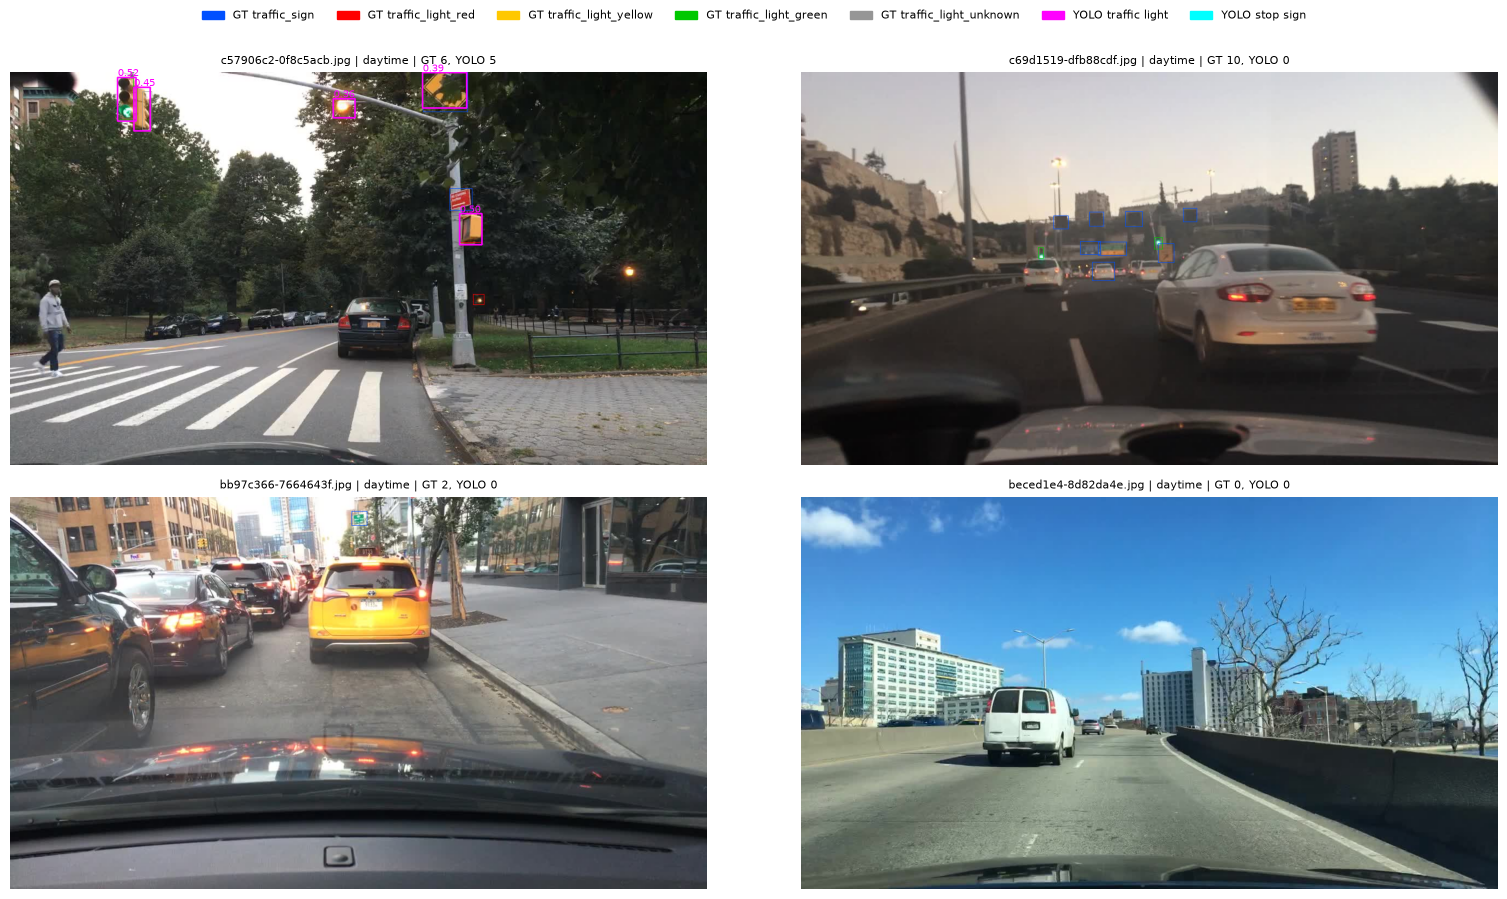

In [7]:
show_yolo(example_preds, examples, model, n=4, seed=0)

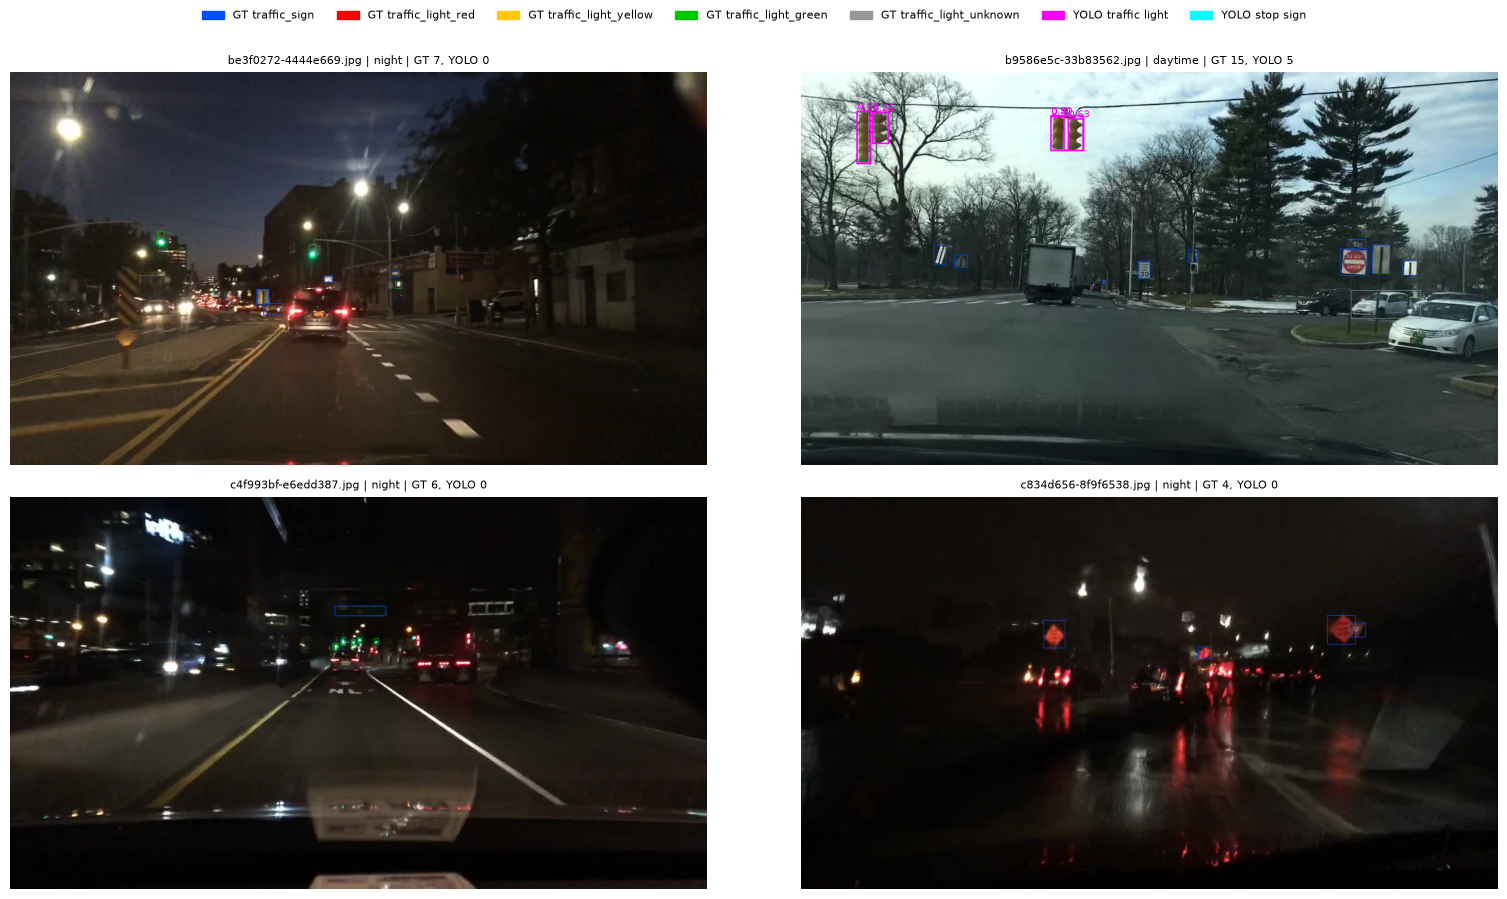

In [8]:
# Harder conditions: night, rain and snow
show_yolo(
    example_preds,
    examples,
    model,
    n=4,
    seed=1,
    where=lambda s: (
        s["attributes"].get("timeofday") == "night"
        or s["attributes"].get("weather") in ("rainy", "snowy")
    ),
)